# From Logistic Regression to a Neural Network

In this notebook, we classify emails as legitimate or spam. We compare logistic regression with a small Multi-Layer Perceptron (MLP) using the same numerical email features. The business question is whether we can identify spam without sending too many legitimate emails for review.

In this notebook, we will:
1. Prepare the email data and scale a shared set of features.
2. Train logistic regression and explain its sigmoid output.
3. Add a hidden layer and compare the models on validation data.
4. Choose decision thresholds and evaluate fixed choices on historical test data.

The optional sections compare XGBoost, pretrained text features and an additional hidden layer. The embedding extension has separate kernel instructions.

A prediction supports a review decision; it is not a reason to delete an email automatically.

## Libraries and settings

Import the libraries, set the random seed and locate the local email data. The same settings and prepared features are used throughout the main comparison.

In [ ]:
from pathlib import Path
from email import policy
from email.parser import Parser
import ast
import hashlib
import importlib.metadata
import re
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 7
MAX_MESSAGES = 30_000
LABEL_MEANINGS = {0: 'ham', 1: 'spam'}
np.random.seed(SEED)
search_roots = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((root for root in search_roots
                  if (root / '00_Data' / 'email_spam.csv').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Open this notebook from inside python_machine_learning_basics; 00_Data/email_spam.csv must be present.')
DATA_DIR = REPO_ROOT / '00_Data'
NOTEBOOK_DIR = REPO_ROOT / '08_Neural_Networks' / 'HS2026'
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
from enron_features import EmailFeatures, FEATURE_NAMES

versions = {package: importlib.metadata.version(package)
            for package in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'joblib']}
print('1. Imports and reproducibility')
print('Data directory:', DATA_DIR)
print('Documented labels:', LABEL_MEANINGS)
display(pd.Series(versions, name='Installed version'))

1. Imports and reproducibility
Data directory: /Users/iaracena/VisualStudioProjects/ZHAW/examples/enron_spam
Documented labels: {0: 'ham', 1: 'spam'}


numpy            2.5.4
pandas           3.0.6
scikit-learn     1.9.1
matplotlib      3.11.2
joblib           1.6.0
Name: Installed version, dtype: str

## Import and prepare the email data

Each observation is one email: **0 = legitimate (ham), 1 = spam**. The included `00_Data/email_spam.csv` contains 16 numeric features for a reproducible sample of 30,000 messages from a combined Enron, TREC and other-source dataset. Raw subjects and bodies are not included.

During preparation, the data helper decodes messages, excludes empty messages, removes normalized exact duplicates and quarantines conflicting-label duplicates before sampling with seed 7. The CSV preserves fixed partitions: **18,000 training, 6,000 validation and 6,000 test emails**. Loading the CSV does not resample it.

Use training data to fit models, validation data to choose settings and thresholds, and test data to evaluate fixed choices. Both models receive the same 16 features; labels, split membership, source rows and message identifiers are not predictors. See the repository README and `00_Data/prepare_data.py` for recreation instructions.

In [ ]:
email_data_path = DATA_DIR / 'email_spam.csv'
prepared_emails = pd.read_csv(email_data_path)

train = prepared_emails.loc[prepared_emails['split'].eq('train')].copy()
validation = prepared_emails.loc[prepared_emails['split'].eq('validation')].copy()
test = prepared_emails.loc[prepared_emails['split'].eq('test')].copy()

print('Loaded:', email_data_path.resolve())
print(f'Ready: {len(train):,} training, {len(validation):,} validation and {len(test):,} test emails.')

Ready: 18,000 training, 6,000 validation and 6,000 test emails.


In [3]:
display(pd.DataFrame({
    'Split': ['Training', 'Validation', 'Test'],
    'Emails': [len(train), len(validation), len(test)],
    'Purpose': ['Fit models', 'Choose settings and thresholds', 'Evaluate fixed choices'],
}))

,Split,Emails,Purpose
0,Training,18000,Fit models
1,Validation,6000,Choose settings and thresholds
2,Test,6000,Evaluate fixed choices


## Prepare the input features

Each email is represented by 16 numbers:
- **Size:** character count, word count, average word length and subject length.
- **Character patterns:** the proportion of uppercase letters and digits.
- **Symbols and links:** counts of exclamation marks, currency symbols, URLs and email addresses.
- **Words:** counts of *free*, *offer*, *winner*, *urgent*, *discount* and *unsubscribe*.

The CSV already contains these deterministic per-message features. `enron_features.py` selects them in a fixed order for both models and calculates the same features from new subjects and bodies when making predictions. These features capture simple patterns, not the meaning of the message.

We then use `StandardScaler` to put the features on comparable scales. **Fit the scaler on training emails only**, then reuse it for validation and test emails. This prevents information from those sets influencing training.

In [ ]:
print('4. Select shared email features')
content_columns = list(FEATURE_NAMES)
train_messages = train[content_columns].copy()
validation_messages = validation[content_columns].copy()
test_messages = test[content_columns].copy()
y_train = train['label'].to_numpy()
y_validation = validation['label'].to_numpy()
y_test = test['label'].to_numpy()
feature_transformer = EmailFeatures()
raw_train_features = feature_transformer.fit_transform(train_messages)
display(raw_train_features.head())
display(raw_train_features.agg(['min', 'median', 'max']).T)
print('Inputs contain only:', train_messages.columns.tolist())

4. Engineer shared email features


,character_count,word_count,average_word_length,uppercase_letter_ratio,digit_ratio,exclamation_count,currency_symbol_count,url_count,email_address_count,subject_length,term_free_count,term_offer_count,term_winner_count,term_urgent_count,term_discount_count,term_unsubscribe_count
235885,4080.0,753.0,4.053121,0.141559,0.100466,8.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0
73282,570.0,110.0,3.781818,0.016990,0.006969,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
112494,496.0,86.0,4.604651,0.069948,0.020121,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49201,485.0,84.0,4.702381,0.058355,0.037037,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
158433,422.0,71.0,4.535211,0.000000,0.014151,0.0,0.0,0.0,0.0,423.0,0.0,0.0,0.0,0.0,0.0,0.0


,min,median,max
character_count,3.000000,666.000000,1.192291e+06
word_count,1.000000,112.000000,1.606380e+05
average_word_length,1.242604,4.515754,5.742593e+01
uppercase_letter_ratio,0.000000,0.069536,1.000000e+00
digit_ratio,0.000000,0.019520,8.333333e-01
exclamation_count,0.000000,0.000000,3.950000e+02
currency_symbol_count,0.000000,0.000000,1.023900e+04
url_count,0.000000,0.000000,4.770000e+02
email_address_count,0.000000,0.000000,3.520000e+02
subject_length,0.000000,0.000000,9.336000e+03


Inputs contain only: ['subject', 'body']


## Scale the input features

Fit the feature extractor and scaler on training emails only, then transform validation and test emails with the same fitted pipeline. The histograms describe selected training features; they do not guide changes using test data.

5. Fit shared preprocessing on training data only
Train / validation / test shapes: (18000, 16) (6000, 16) (6000, 16)


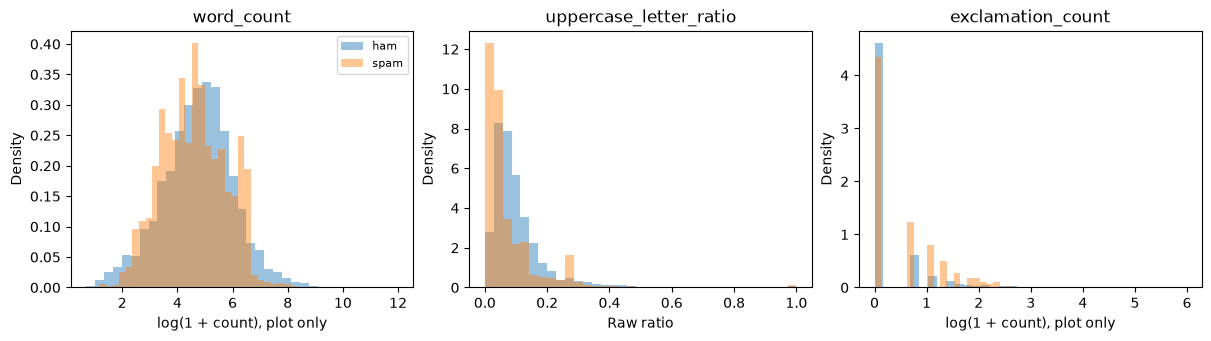

In [ ]:
print('5. Fit shared preprocessing on training data only')
preprocessing = Pipeline([('features', EmailFeatures()), ('scale', StandardScaler())])
X_train = preprocessing.fit_transform(train_messages, y_train)
X_validation = preprocessing.transform(validation_messages)
X_test = preprocessing.transform(test_messages)
feature_names = preprocessing.named_steps['features'].get_feature_names_out()
print('Train / validation / test shapes:', X_train.shape, X_validation.shape, X_test.shape)
figure, axes = plt.subplots(1, 3, figsize=(12, 3.3), constrained_layout=True)
for axis, feature in zip(axes, ['word_count', 'uppercase_letter_ratio', 'exclamation_count']):
    for label, name in LABEL_MEANINGS.items():
        values = raw_train_features.loc[y_train == label, feature]
        if feature != 'uppercase_letter_ratio':
            values = np.log1p(values)
        axis.hist(values, bins=35, density=True, alpha=0.45, label=name)
    axis.set_title(feature)
    axis.set_xlabel('Raw ratio' if feature == 'uppercase_letter_ratio' else 'log(1 + count), plot only')
    axis.set_ylabel('Density')
axes[0].legend(fontsize=8)
plt.show()

## Train the logistic regression model

The model multiplies each feature by a learned weight and adds a bias. A **sigmoid** turns this score into an estimated spam probability:

$$z=\mathbf{w}^{T}\mathbf{x}+b,\qquad p=\frac{1}{1+\exp(-z)}.$$

Here, $\mathbf{x}$ contains the 16 scaled features, $\mathbf{w}$ contains their weights and $b$ is the bias. That gives **17 trainable parameters**. The next cell checks the prediction calculation against scikit-learn.

We compare the model with a **baseline that uses only the training-set spam proportion**. On validation data, read:
- **Precision:** of the emails flagged as spam, how many really are spam?
- **Recall:** of all spam emails, how many did we flag?
- **F1:** a single score combining precision and recall.
- **Average precision (AP):** how well does the model rank spam ahead of legitimate emails across thresholds?

A probability is not yet a decision. We choose the decision threshold later; probability calibration would need a separate check.

<details>
<summary>Optional: the training loss</summary>

For a true label $y$ (0 or 1) and predicted probability $p$, binary cross-entropy is

$$L(y,p)=-[y\log p+(1-y)\log(1-p)].$$

Training reduces this loss together with a regularization penalty. The manual calculation above reproduces prediction, not the training algorithm.

</details>

In [ ]:
print('6. Logistic regression as a single output neuron')
logistic = LogisticRegression(C=1.0, max_iter=1500, random_state=SEED)
with warnings.catch_warnings(record=True) as logistic_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    logistic.fit(X_train, y_train)
for warning in logistic_warnings:
    print(type(warning.message).__name__, str(warning.message))
weighted_sum = X_validation[:5] @ logistic.coef_[0] + logistic.intercept_[0]
manual_probability = np.exp(-np.logaddexp(0, -weighted_sum))
print('Parameters:', logistic.coef_.size + logistic.intercept_.size)
display(pd.DataFrame({'weighted_sum': weighted_sum, 'manual_sigmoid': manual_probability,
                      'predict_proba': logistic.predict_proba(X_validation[:5])[:, 1]}))

6. Logistic regression as a single output neuron
Parameters: 17


,weighted_sum,manual_sigmoid,predict_proba
0,-0.747741,0.321314,0.321314
1,0.364632,0.590161,0.590161
2,1.161086,0.761530,0.761530
3,-1.001909,0.268566,0.268566
4,-1.765360,0.146120,0.146120


7. Validation evaluation and feature weights


,precision,recall,f1,average_precision,flagged_fraction
Prior baseline,0.000000,0.000000,0.000000,0.296667,0.0000
Logistic regression,0.740916,0.263483,0.388728,0.599288,0.1055


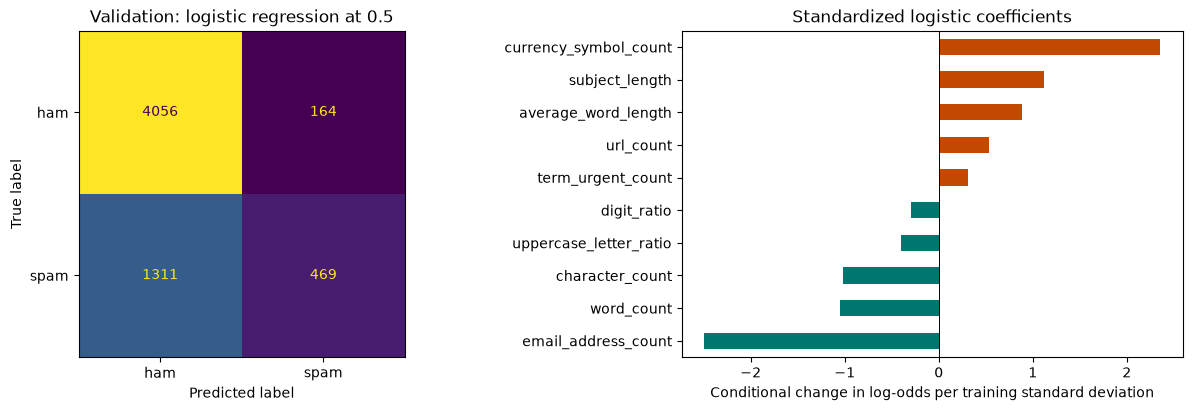

Coefficients describe model associations, not causal effects. Correlated counts make attribution unstable.


In [7]:
print('7. Validation evaluation and feature weights')


def metrics_at_threshold(targets, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {'precision': precision_score(targets, predictions, zero_division=0),
            'recall': recall_score(targets, predictions, zero_division=0),
            'f1': f1_score(targets, predictions, zero_division=0),
            'average_precision': average_precision_score(targets, probabilities),
            'flagged_fraction': float(predictions.mean())}


baseline = DummyClassifier(strategy='prior', random_state=SEED).fit(X_train, y_train)
validation_probabilities = {
    'Prior baseline': baseline.predict_proba(X_validation)[:, 1],
    'Logistic regression': logistic.predict_proba(X_validation)[:, 1],
}
display(pd.DataFrame({name: metrics_at_threshold(y_validation, probabilities)
                      for name, probabilities in validation_probabilities.items()}).T)
figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(y_validation, validation_probabilities['Logistic regression'] >= 0.5,
                                        display_labels=['ham', 'spam'], ax=axes[0], colorbar=False)
axes[0].set_title('Validation: logistic regression at 0.5')
coefficients = pd.Series(logistic.coef_[0], index=feature_names).sort_values()
coefficient_subset = pd.concat([coefficients.head(5), coefficients.tail(5)]).drop_duplicates().sort_values()
coefficient_subset.plot.barh(ax=axes[1], color=['#C34800' if value > 0 else '#00776E' for value in coefficient_subset])
axes[1].axvline(0, color='black', linewidth=0.7)
axes[1].set_title('Standardized logistic coefficients')
axes[1].set_xlabel('Conditional change in log-odds per training standard deviation')
plt.show()
print('Coefficients describe model associations, not causal effects. Correlated counts make attribution unstable.')

## Train the Multi-Layer Perceptron (MLP) model

The inputs stay the same. The neural network, also called an **MLP**, adds a layer that learns combinations of those features:

**16 email features → 8 or 16 ReLU units → 1 sigmoid output**

- **ReLU** replaces a negative value with zero and leaves a positive value unchanged.
- **Backpropagation** calculates how each weight affects the loss.
- **Adam** uses those gradients to update the weights in small batches.

We try two hidden-layer sizes and choose the model with the better **validation AP**. A lower training loss alone does not show that the model works better on new emails.

The network still receives counts and ratios, not raw words. More hidden units do not guarantee better results. The two model types also use different training procedures, so this comparison does not isolate architecture alone.

8. Neural networks on the identical feature matrices
Hidden size 8: 200 epochs; warnings: ["Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet."]
Hidden size 16: 200 epochs; warnings: ["Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet."]


,epochs,validation_ap,warnings
hidden_units,,,
8,200,0.800129,1
16,200,0.835271,1


Selected hidden size: 16
Weight shapes: [(16, 16), (16, 1)]
Bias shapes: [(16,), (1,)]
Output activation: logistic
MLP parameters: 289


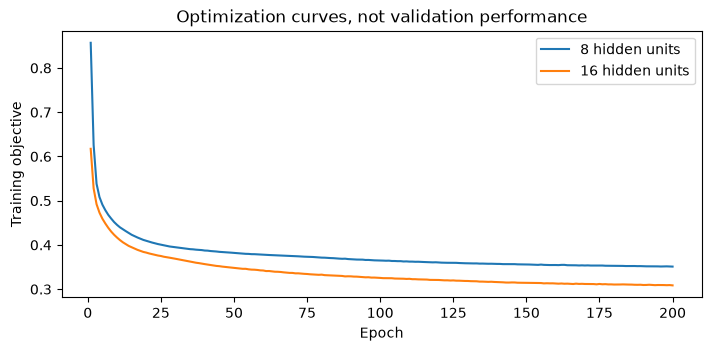

In [ ]:
print('8. Neural networks on the identical feature matrices')
network_candidates = {}
network_records = []
for hidden_size in [8, 16]:
    candidate = MLPClassifier(hidden_layer_sizes=(hidden_size,), activation='relu', solver='adam',
                              alpha=0.01, batch_size=128, learning_rate_init=0.001,
                              max_iter=200, n_iter_no_change=15, early_stopping=False,
                              random_state=SEED)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        candidate.fit(X_train, y_train)
    messages = [str(warning.message) for warning in caught]
    print(f'Hidden size {hidden_size}: {candidate.n_iter_} epochs; warnings: {messages or "none"}')
    probabilities = candidate.predict_proba(X_validation)[:, 1]
    network_candidates[hidden_size] = candidate
    network_records.append({'hidden_units': hidden_size, 'epochs': candidate.n_iter_,
                            'validation_ap': average_precision_score(y_validation, probabilities),
                            'warnings': len(messages)})
network_comparison = pd.DataFrame(network_records).set_index('hidden_units')
display(network_comparison)
best_size = int(network_comparison['validation_ap'].idxmax())
network = network_candidates[best_size]
print('Selected hidden size:', best_size)
print('Weight shapes:', [weights.shape for weights in network.coefs_])
print('Bias shapes:', [bias.shape for bias in network.intercepts_])
print('Output activation:', network.out_activation_)
print('MLP parameters:', sum(weights.size for weights in network.coefs_) + sum(bias.size for bias in network.intercepts_))
hidden = np.maximum(0, X_validation[:5] @ network.coefs_[0] + network.intercepts_[0])
output_score = hidden @ network.coefs_[1] + network.intercepts_[1]
manual_network_probability = np.exp(-np.logaddexp(0, -output_score)).ravel()
figure, axis = plt.subplots(figsize=(7, 3.4), constrained_layout=True)
for size, candidate in network_candidates.items():
    axis.plot(np.arange(1, len(candidate.loss_curve_) + 1), candidate.loss_curve_, label=f'{size} hidden units')
axis.set(xlabel='Epoch', ylabel='Training objective', title='Optimization curves, not validation performance')
axis.legend()
plt.show()

## Optional comparison: XGBoost

**XGBoost is a tree model, not a neural network.** It adds small decision trees one after another to improve predictions.

It receives the same 16 features and appears in the comparison table below. The settings are fixed: 200 trees, depth 3 and learning rate 0.05. Trees do not usually need scaling; we keep the shared inputs unchanged here.

**Question:** Does a neural network perform better than a strong tree-based model on these features?

Treat this as an exploratory comparison: it was added after earlier test results had been inspected. Different model sizes and training procedures also limit what we can conclude. A stronger comparison needs fresh evaluation data.

<details>
<summary>Setup and official documentation</summary>

Use the pinned `xgboost` dependency. On macOS, its native library also requires `libomp` (`brew install libomp`).

[XGBClassifier API](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBClassifier) · [Model tutorial](https://xgboost.readthedocs.io/en/stable/tutorials/model.html) · [Installation guide](https://xgboost.readthedocs.io/en/stable/install.html)

</details>

In [ ]:
print('8b. XGBoost on the identical feature matrices')
from xgboost import XGBClassifier

versions['xgboost'] = importlib.metadata.version('xgboost')
print('XGBoost version:', versions['xgboost'])
xgboost_model = XGBClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    min_child_weight=5, subsample=1.0, colsample_bytree=1.0,
    reg_lambda=1.0, objective='binary:logistic', eval_metric='logloss',
    tree_method='hist', n_jobs=1, random_state=SEED,
)
xgboost_model.fit(X_train, y_train)
xgboost_validation_probability = xgboost_model.predict_proba(X_validation)[:, 1]
validation_probabilities['Neural network'] = network.predict_proba(X_validation)[:, 1]
validation_probabilities['XGBoost'] = xgboost_validation_probability
display(pd.DataFrame({name: metrics_at_threshold(y_validation, probabilities)
                      for name, probabilities in validation_probabilities.items()}).T.round(4))

8b. XGBoost on the identical feature matrices
XGBoost version: 3.4.1


,precision,recall,f1,average_precision,flagged_fraction
Prior baseline,0.0000,0.0000,0.0000,0.2967,0.0000
Logistic regression,0.7409,0.2635,0.3887,0.5993,0.1055
Neural network,0.8180,0.7270,0.7698,0.8353,0.2637
XGBoost,0.8475,0.7056,0.7701,0.8726,0.2470


## Select decision thresholds

An email is flagged when its estimated spam probability reaches a **threshold**. Changing that threshold changes how many emails are flagged and how many mistakes we make.

For this example, assume:
- Flagging a legitimate email costs **5 units**.
- Missing a spam email costs **1 unit**.

We choose each model's threshold on **validation data** to reduce `5 × false positives + false negatives`. These are example costs, not measured financial losses. The no-skill baseline keeps its threshold of 0.5.

Then we keep the models and thresholds fixed and evaluate the test set. **Do not use test results to adjust them.** AP measures ranking; the threshold and error costs determine this review policy's outcome.

In [12]:
print('9a. Freeze thresholds using validation only')
FALSE_POSITIVE_COST = 5
FALSE_NEGATIVE_COST = 1
models = {'Prior baseline': baseline, 'Logistic regression': logistic,
          'Neural network': network, 'XGBoost': xgboost_model}
validation_probabilities = {name: model.predict_proba(X_validation)[:, 1] for name, model in models.items()}
thresholds = {'Prior baseline': 0.5}
threshold_records = []
for name in ['Logistic regression', 'Neural network', 'XGBoost']:
    probabilities = validation_probabilities[name]
    candidates = []
    for threshold in np.linspace(0.05, 0.95, 91):
        true_negative, false_positive, false_negative, true_positive = confusion_matrix(
            y_validation, probabilities >= threshold, labels=[0, 1]).ravel()
        cost = FALSE_POSITIVE_COST * false_positive + FALSE_NEGATIVE_COST * false_negative
        candidates.append((cost, float(threshold)))
    best_cost, best_threshold = min(candidates)
    thresholds[name] = best_threshold
for name, probabilities in validation_probabilities.items():
    selected_threshold = thresholds[name]
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        y_validation, probabilities >= selected_threshold, labels=[0, 1]).ravel()
    threshold_records.append({'model': name, 'threshold': selected_threshold,
                              'cost_per_1000': 1000 * (FALSE_POSITIVE_COST * false_positive + FALSE_NEGATIVE_COST * false_negative) / len(y_validation),
                              **metrics_at_threshold(y_validation, probabilities, selected_threshold)})
display(pd.DataFrame(threshold_records).set_index('model'))
print('Frozen architecture:', network.hidden_layer_sizes, '| thresholds:', thresholds)

9a. Freeze thresholds using validation only


,threshold,cost_per_1000,precision,recall,f1,average_precision,flagged_fraction
model,,,,,,,
Prior baseline,0.50,296.666667,0.000000,0.000000,0.000000,0.296667,0.000000
Logistic regression,0.95,295.666667,0.854167,0.023034,0.044858,0.599288,0.008000
Neural network,0.82,232.833333,0.915276,0.400562,0.557249,0.835271,0.129833
XGBoost,0.74,201.500000,0.942595,0.461236,0.619389,0.872627,0.145167


Frozen architecture: (16,) | thresholds: {'Prior baseline': 0.5, 'Logistic regression': 0.95, 'Neural network': 0.82, 'XGBoost': 0.74}


## Evaluate the trained models

Compare the fixed models and validation-selected thresholds on historical test emails. Read precision, recall, average precision and the assumed error costs together. Keep the choices fixed after viewing these results; extensions added after test inspection remain exploratory.

9b. Held-out test comparison: no further tuning


,threshold,precision,recall,f1,average_precision,flagged_fraction,false_positives,false_negatives,cost_per_1000
model,,,,,,,,,
Prior baseline,0.50,0.0000,0.0000,0.0000,0.2967,0.0000,0,1780,296.6667
Logistic regression,0.95,0.7931,0.0258,0.0501,0.5843,0.0097,12,1734,299.0000
Neural network,0.82,0.9245,0.3921,0.5507,0.8356,0.1258,57,1082,227.8333
XGBoost,0.74,0.9424,0.4506,0.6097,0.8580,0.1418,49,978,203.8333


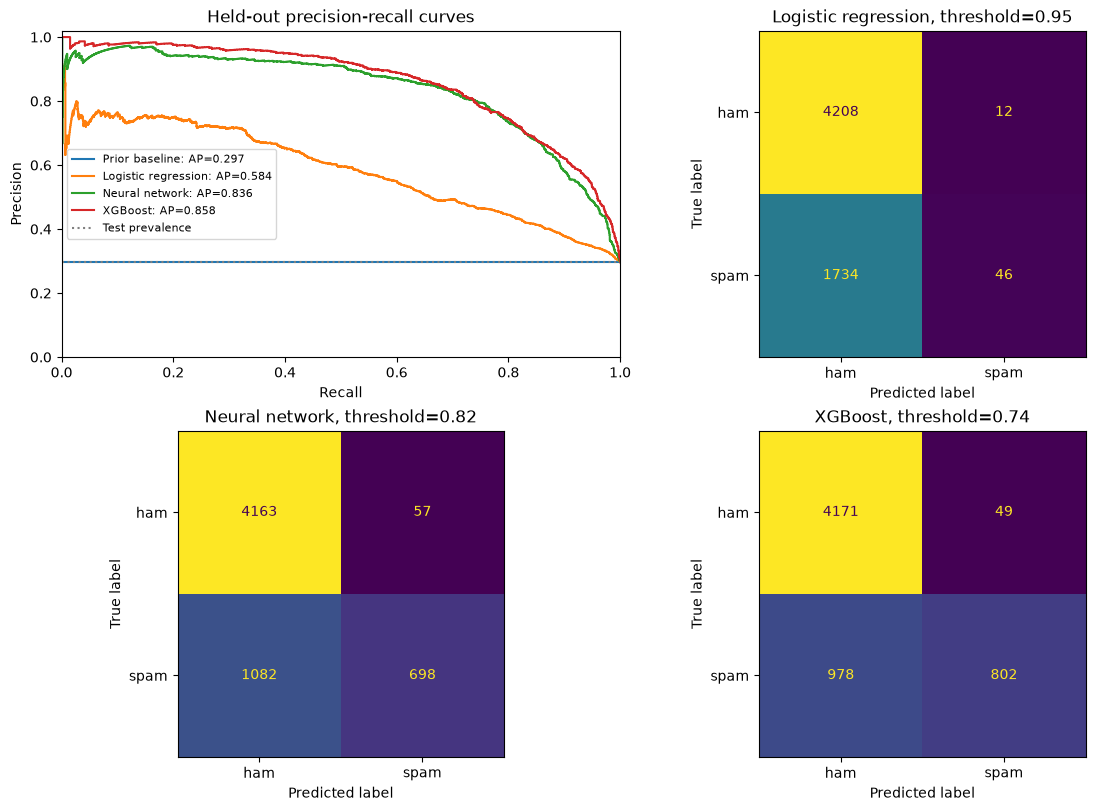

Test results estimate performance on exchangeable historical messages, not deployment or causal effects.
XGBoost was added after earlier test results were inspected; this extension is exploratory, not fresh confirmation.


In [13]:
print('9b. Held-out test comparison: no further tuning')
test_probabilities = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}
test_records = []
for name, probabilities in test_probabilities.items():
    threshold = thresholds[name]
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        y_test, probabilities >= threshold, labels=[0, 1]).ravel()
    test_records.append({'model': name, 'threshold': threshold,
                         **metrics_at_threshold(y_test, probabilities, threshold),
                         'false_positives': false_positive, 'false_negatives': false_negative,
                         'cost_per_1000': 1000 * (FALSE_POSITIVE_COST * false_positive + FALSE_NEGATIVE_COST * false_negative) / len(y_test)})
test_results = pd.DataFrame(test_records).set_index('model')
display(test_results.round(4))
figure, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes = axes.ravel()
for name, probabilities in test_probabilities.items():
    precision, recall, curve_thresholds = precision_recall_curve(y_test, probabilities)
    axes[0].step(recall, precision, where='post',
                 label=f'{name}: AP={average_precision_score(y_test, probabilities):.3f}')
axes[0].axhline(y_test.mean(), color='gray', linestyle=':', label='Test prevalence')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Held-out precision-recall curves', xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8)
for axis, name in zip(axes[1:], ['Logistic regression', 'Neural network', 'XGBoost']):
    ConfusionMatrixDisplay.from_predictions(y_test, test_probabilities[name] >= thresholds[name],
                                            display_labels=['ham', 'spam'], ax=axis, colorbar=False)
    axis.set_title(f'{name}, threshold={thresholds[name]:.2f}')
plt.show()
print('Test results estimate performance on exchangeable historical messages, not deployment or causal effects.')
print('XGBoost was added after earlier test results were inspected; this extension is exploratory, not fresh confirmation.')

In [16]:
print('9c. Inspect limited false positives and false negatives without exposing email text')
network_predictions = test_probabilities['Neural network'] >= thresholds['Neural network']
error_rows = test[['label', 'source_row']].copy()
error_rows['spam_probability'] = test_probabilities['Neural network']
error_rows['predicted_label'] = network_predictions.astype(int)
error_features = preprocessing.named_steps['features'].transform(test_messages)
for error_name, mask in [('False positives', (y_test == 0) & network_predictions),
                         ('False negatives', (y_test == 1) & ~network_predictions)]:
    positions = np.flatnonzero(mask)[:3]
    print(error_name, '- first three in fixed test order, not representative samples')
    display(error_rows.iloc[positions].join(error_features[['word_count', 'uppercase_letter_ratio',
                                                           'url_count', 'term_free_count']]))
print('Raw subject/body content is withheld rather than incompletely redacted. Source rows enable authorized local review.')

9c. Inspect limited false positives and false negatives without exposing email text
False positives - first three in fixed test order, not representative samples


,label,source_row,spam_probability,predicted_label,word_count,uppercase_letter_ratio,url_count,term_free_count
18333,0,18333,0.838009,1,9.0,0.025641,2.0,0.0
226634,0,226634,0.994037,1,510.0,0.061622,0.0,0.0
260709,0,260709,0.962735,1,941.0,0.075532,0.0,0.0


False negatives - first three in fixed test order, not representative samples


,label,source_row,spam_probability,predicted_label,word_count,uppercase_letter_ratio,url_count,term_free_count
89691,1,89691,0.204537,0,119.0,0.046847,0.0,0.0
166075,1,166075,0.596306,0,21.0,0.000000,0.0,0.0
45194,1,45194,0.739087,0,104.0,0.055336,1.0,0.0


Raw subject/body content is withheld rather than incompletely redacted. Source rows enable authorized local review.


## Save and reuse the trained models

Save the fitted feature extractor, scaler and classifier together. Also save the decision threshold, feature names and package versions so predictions can be reproduced.

The saved pipeline takes a table with `subject` and `body` columns. Reading a CSV or decoding an email happens before that step; `enron_features.py` must remain available.

**Only load trusted joblib files:** loading a model file can execute code. Protect model files as well as the original emails.

The made-up messages below illustrate possible failures. They are not a new test set, and their predictions are not guaranteed to be correct.

In [ ]:
print('10. Save, reload, and test the complete fitted pipelines')
model_directory = DATA_DIR / 'models'
model_directory.mkdir(exist_ok=True)
synthetic_messages = pd.DataFrame({
    'subject': ['Project meeting', 'FREE OFFER!', '', 'Unicode probe'],
    'body': ['Please review the quarterly forecast before our meeting tomorrow.',
             'WINNER! Claim your free $100 offer at https://example.invalid now!',
             '', 'Gr\u00fcsse, \u6771\u4eac! Price \u20ac20. Visit https : //example.invalid'],
}, index=['business-style probe', 'promotion-style probe', 'empty probe', 'Unicode probe'])
synthetic_features = feature_transformer.transform(synthetic_messages)
synthetic_results = pd.DataFrame(index=synthetic_messages.index)
saved_pipelines = {}
artifact_filenames = {'Logistic regression': 'logistic_regression.joblib',
                      'Neural network': 'neural_network.joblib', 'XGBoost': 'xgboost.joblib'}
for name, filename in artifact_filenames.items():
    estimator = models[name]
    fitted_pipeline = Pipeline([('preprocessing', preprocessing), ('model', estimator)])
    original_probabilities = fitted_pipeline.predict_proba(synthetic_messages)[:, 1]
    artifact = {'pipeline': fitted_pipeline, 'threshold': thresholds[name], 'seed': SEED,
                'feature_names': list(feature_names), 'versions': versions,
                'label_meanings': LABEL_MEANINGS, 'python': sys.version,
                'input_schema': ['subject', 'body'],
                'label_mapping_basis': 'Course README: 0=ham, 1=spam',
                'dataset_file': str(email_data_path.relative_to(REPO_ROOT))}
    artifact_path = model_directory / filename
    joblib.dump(artifact, artifact_path)
    restored = joblib.load(artifact_path)
    restored_probabilities = restored['pipeline'].predict_proba(synthetic_messages)[:, 1]
    saved_pipelines[name] = restored['pipeline']
    synthetic_results[name + ' probability'] = restored_probabilities
    synthetic_results[name + ' flagged'] = restored_probabilities >= restored['threshold']
    print('Saved:', artifact_path.name)
display(synthetic_results.round(4))
print('Saved fitted pipelines and generated synthetic predictions.')

10. Save, reload, and test the complete fitted pipelines
Saved and verified: logistic_regression.joblib
Saved and verified: neural_network.joblib
Saved and verified: xgboost.joblib


,Logistic regression probability,Logistic regression flagged,Neural network probability,Neural network flagged,XGBoost probability,XGBoost flagged
business-style probe,0.7351,False,0.7970,False,0.7945,True
promotion-style probe,0.3577,False,0.2464,False,0.9624,True
empty probe,0.0366,False,0.6919,False,0.0868,False
Unicode probe,0.4740,False,0.8492,True,0.8850,True


All finite-value, shared-feature, manual-forward-pass, and serialization checks passed.


## Summary and exercises

- Logistic regression uses one sigmoid output. The neural network adds a hidden layer but keeps the same 16 inputs.
- Read **AP, precision, recall and error cost** together. A better ranking does not always give a better review policy.
- A model can give a number for an empty or unfamiliar email without giving a useful prediction. The made-up messages illustrate this problem.

### Limits to remember
- Simple counts miss meaning; subjects are often missing and email parsing is imperfect.
- Related messages or campaigns may still appear in different splits. A random split does not prove the model will work on future email.
- One small comparison does not show that neural networks are always better. Training warnings may mean the network has not converged.
- Public email data can contain personal information. Protect the data and saved models. Features and hashed identifiers are not a guarantee of anonymization.
- Model weights describe associations, **not causes**. Deployment would need further testing, probability checks and monitoring.

## Check your understanding
1. Why must the scaler be fitted on training data only?
2. What does the hidden layer add, and what stays the same?
3. How many parameters are in a network with 16 inputs, 8 hidden units and one output?
4. Why can better AP still give poor business value?
5. Should we change the model just to make one made-up email look correct?

<details>
<summary>Answers and self-check criteria</summary>

1. **Basic, 2 points:** avoid leakage (1); fit on training data and only transform validation/test data (1). Common mistake: fitting a separate scaler to each split.
2. **Basic, 3 points:** the inputs stay the same (1); hidden ReLU units learn feature combinations (1); the sigmoid output stays (1). Common mistake: assuming the network now reads raw words.
3. **Intermediate, 2 points:** weights: $16\times8+8\times1=136$ (1); biases: $8+1=9$, giving **145 parameters** (1). Common mistake: forgetting biases.
4. **Intermediate, 3 points:** AP measures ranking (1); a threshold determines errors (1); costs and review capacity determine value (1). Common mistake: treating AP as a cost saving.
5. **Advanced, 3 points:** the example reveals a possible limitation (1), not benchmark performance (1); improvements need new training/validation work and independent evaluation (1). Common mistake: tuning on the test set or on one example.

</details>

### Optional exercise
Compare a `log1p` count transformation or a TF-IDF logistic baseline. The count transformation works with the included CSV; TF-IDF requires private raw text and the same verified splits. Change one factor at a time. Plan fresh evaluation data before using previous test results to guide changes.

<details>
<summary>Dataset details and further reading</summary>

**Dataset:** NIKHIL CHAUDHARY 7108. (n.d.). *Spam email dataset(ENRON , TREC and others)*. [Kaggle dataset page](https://www.kaggle.com/datasets/nikhilchaudhary7108/spam-email-datasetenron-trec-and-others), accessed 18 October 2026. The publisher lists Version 2, 298,166 messages, 0=ham / 1=spam and Apache 2.0. The collection combines Enron, TREC and other Kaggle sources. Its upstream rights, labels and exact version match have not been independently audited. The included `00_Data/email_spam.csv` contains 30,000 feature-only records derived from a trusted local `email_data.csv`. Preparation recomputes 16 per-message features, removes empty and normalized exact-duplicate messages and quarantines conflicting labels before sampling and splitting with seed 7. Near-duplicates may remain. The CSV retains fixed split membership, original source-row numbers and normalized-message hashes, but no raw email text or local filesystem paths. Recreate it with `python 00_Data/prepare_data.py --email-source /path/to/email_data.csv`; learned scaling is fitted only in the notebook on training data.

**Required student reading:** James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An Introduction to Statistical Learning: With Applications in Python*. Springer. Selected classification and deep-learning material. https://www.statlearning.com/

**Optional interpretation reading / instructor reference:** Molnar, C. *Interpretable Machine Learning*, 2nd ed. Coefficients and interpretation limitations. https://christophm.github.io/interpretable-ml-book/

**Official technical documentation:**
- scikit-learn: [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html), [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html) and [safe model persistence](https://scikit-learn.org/stable/model_persistence.html).
- Python: [`ast.literal_eval` and its resource limits](https://docs.python.org/3/library/ast.html#ast.literal_eval). The raw-data loader is for trusted local files, not arbitrary uploads.

</details>

In [ ]:
requirements_path = REPO_ROOT / 'requirements.txt'
print('Repository base requirements:')
print(requirements_path.read_text())
print('Installed packages used in the main notebook:')
display(pd.Series(versions, name='Installed version'))
print('Optional XGBoost and text-embedding packages are additional dependencies.')

The current kernel matches all pinned dependencies.


## Optional extension: learn from pretrained text features

**Question:** Would features that capture more of an email's meaning help more than our 16 counts?

We use `sentence-transformers/all-MiniLM-L6-v2` to turn each subject and body into **384 numbers**, called an embedding. The encoder stays fixed. We train only a small MLP with 32 hidden units and one binary output. Encoding runs locally after the model is downloaded; emails are not sent to a hosted inference API.

**Additional inputs:** the feature-only course CSV cannot reconstruct email text. This extension requires an authorized private copy of the original raw CSV and the additional `sentence-transformers`, `transformers`, `torch` and `huggingface-hub` packages. Keep the raw corpus outside the repository.

### Run in a separate session
1. Restart the kernel.
2. Run **Libraries and settings** and **Import and prepare the email data** to load the reference splits.
3. Set `RAW_EMAIL_PATH` in the next code cell to the trusted local raw CSV. The loader checks message identifiers, labels and source-row numbers against every reference split before loading the encoder.
4. Run the four code cells directly below this explanation. Do not run XGBoost in this session.

Use a separate session to avoid mixing the earlier model-loading path with this experiment. The first embedding run is slower; later runs reuse a checked feature cache.

### Read the comparison carefully
- Only the first 256 tokens, including special tokens, are used; long emails are cut short.
- The MLP uses part of its training data for early stopping. The outer validation set chooses the threshold using the same 5:1 error costs.
- Pretraining, input features and model size all differ. Results are exploratory because the test data were already inspected.

<details>
<summary>Saved files, limitations and references</summary>

The final code cell saves the classifier, encoder settings, predictions and metrics in `00_Data/models/`; feature caches are generated in `00_Data/.embedding_cache/`. Reusing the classifier also requires the same encoder revision, token limit, text format and normalization; the saved classifier alone is not a raw-text pipeline. Protect cached embeddings and model files, and load only trusted joblib files. Overlap with the encoder's pretraining data has not been audited.

[Model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) · [Encoding API](https://www.sbert.net/docs/package_reference/sentence_transformer/SentenceTransformer.html) · [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)

</details>

In [ ]:
print('11a. Load private text and a frozen sentence transformer')
import json
import time
from enron_data import load_email_splits

RAW_EMAIL_PATH = None
if RAW_EMAIL_PATH is None:
    raise FileNotFoundError('Set RAW_EMAIL_PATH to your trusted local email_data.csv path for this optional experiment. The course CSV contains features, not raw text.')
raw_splits = load_email_splits(Path(RAW_EMAIL_PATH), max_messages=MAX_MESSAGES, seed=SEED)
for reference_frame, raw_frame in zip((train, validation, test), raw_splits):
    if not {'subject', 'body'}.issubset(raw_frame.columns):
        raise ValueError('This extension requires raw email text, not the prepared feature CSV.')
    identity_columns = ['message_key', 'label', 'source_row']
    if not reference_frame[identity_columns].reset_index(drop=True).equals(raw_frame[identity_columns].reset_index(drop=True)):
        raise ValueError('The private raw source does not reproduce the reference email splits.')
train, validation, test = raw_splits

import torch
from huggingface_hub import HfApi
from sentence_transformers import SentenceTransformer

EMBEDDING_MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'
EMBEDDING_REVISION = HfApi().model_info(EMBEDDING_MODEL_ID).sha
EMBEDDING_MAX_TOKENS = 256
EMBEDDING_DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
torch.manual_seed(SEED)
torch.set_num_threads(4)
embedding_versions = {package: importlib.metadata.version(package) for package in
                      ['sentence-transformers', 'transformers', 'torch', 'huggingface-hub']}
encoder = SentenceTransformer(EMBEDDING_MODEL_ID, revision=EMBEDDING_REVISION,
                              device=EMBEDDING_DEVICE, trust_remote_code=False)
encoder.max_seq_length = EMBEDDING_MAX_TOKENS
encoder.eval()
for parameter in encoder.parameters():
    parameter.requires_grad_(False)
probe_embeddings = encoder.encode(['Quarterly planning meeting.', 'Claim a free offer!'],
                                   normalize_embeddings=True, convert_to_numpy=True,
                                   show_progress_bar=False)
print('Encoder:', EMBEDDING_MODEL_ID, '| revision:', EMBEDDING_REVISION)
print('Device:', EMBEDDING_DEVICE, '| maximum input tokens:', encoder.max_seq_length)
print('Probe shape:', probe_embeddings.shape)
display(pd.Series(embedding_versions, name='Embedding environment'))

11a. Load a frozen sentence transformer


/Users/iaracena/VisualStudioProjects/ZHAW/.venv-1/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1018 23:44:49.878000 85095 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9107.86it/s]


Encoder: sentence-transformers/all-MiniLM-L6-v2 | revision: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
Device: mps | maximum input tokens: 256
Probe shape: (2, 384)


sentence-transformers     6.1.0
transformers             5.20.1
torch                    2.14.1
huggingface-hub          1.33.0
Name: Embedding environment, dtype: str

In [ ]:
print('11b. Encode raw subject and body, without engineered features')
embedding_cache_directory = DATA_DIR / '.embedding_cache'
embedding_cache_directory.mkdir(exist_ok=True)
embedding_settings = {'model_id': EMBEDDING_MODEL_ID, 'revision': EMBEDDING_REVISION,
                      'max_tokens': EMBEDDING_MAX_TOKENS, 'normalize_embeddings': True,
                      'device': EMBEDDING_DEVICE, 'versions': embedding_versions,
                      'text_format': 'subject + newline + body; strip outer whitespace'}
embedding_matrices = {}
embedding_cache_records = []
for split_name, frame in [('train', train), ('validation', validation), ('test', test)]:
    text_columns = frame[['subject', 'body']].fillna('')
    text_inputs = (text_columns['subject'] + '\n' + text_columns['body']).str.strip()
    fingerprint = hashlib.sha256(json.dumps(embedding_settings, sort_keys=True).encode())
    for text_input in text_inputs:
        encoded_text = text_input.encode('utf-8')
        fingerprint.update(len(encoded_text).to_bytes(8, 'big'))
        fingerprint.update(encoded_text)
    input_digest = fingerprint.hexdigest()
    cache_path = embedding_cache_directory / f'{split_name}_{input_digest}.npz'
    start_time = time.perf_counter()
    cache_hit = cache_path.exists()
    if cache_hit:
        with np.load(cache_path, allow_pickle=False) as cached:
            embeddings = cached['embeddings']
    else:
        embeddings = encoder.encode(text_inputs.tolist(), batch_size=64, normalize_embeddings=True,
                                    convert_to_numpy=True, show_progress_bar=True)
        np.savez_compressed(cache_path, embeddings=embeddings,
                            source_rows=frame['source_row'].to_numpy())
    embedding_matrices[split_name] = embeddings
    embedding_cache_records.append({'split': split_name, 'rows': len(frame), 'dimensions': 384,
                                    'cache_hit': cache_hit, 'seconds': time.perf_counter() - start_time})
    print(split_name, embeddings.shape, '| cached:', cache_hit, flush=True)
display(pd.DataFrame(embedding_cache_records).set_index('split').round(2))
print('No spam labels were supplied to the encoder; no encoder weights were updated.')

11b. Encode raw subject and body, without engineered features
train (18000, 384) | cached: True
validation (6000, 384) | cached: True
test (6000, 384) | cached: True


,rows,dimensions,cache_hit,seconds
split,,,,
train,18000,384,True,0.12
validation,6000,384,True,0.03
test,6000,384,True,0.04


No spam labels were supplied to the encoder; no encoder weights were updated.


11c. Fit an MLP on frozen embeddings


Epochs: 105 | training seconds: 5.77
Validation AP: 0.9838
Frozen threshold: 0.8899999999999999 | validation cost per 1000: 73.0
Classifier parameters: 12353


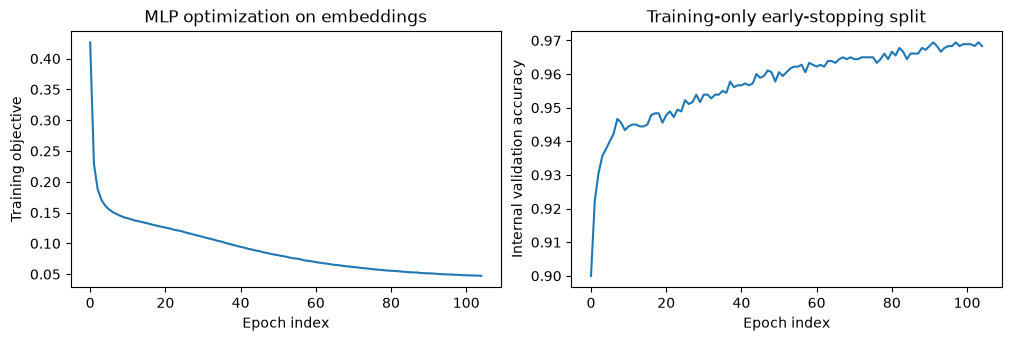

In [ ]:
print('11c. Fit an MLP on frozen embeddings')
embedding_train_labels = train['label'].to_numpy()
embedding_validation_labels = validation['label'].to_numpy()
embedding_test_labels = test['label'].to_numpy()
embedding_classifier = MLPClassifier(
    hidden_layer_sizes=(32,), activation='relu', solver='adam', alpha=0.01,
    batch_size=128, learning_rate_init=0.001, max_iter=150,
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=12, random_state=SEED,
)
embedding_training_start = time.perf_counter()
with warnings.catch_warnings(record=True) as embedding_training_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    embedding_classifier.fit(embedding_matrices['train'], embedding_train_labels)
for warning in embedding_training_warnings:
    print(type(warning.message).__name__, str(warning.message))
embedding_training_seconds = time.perf_counter() - embedding_training_start
embedding_validation_probability = embedding_classifier.predict_proba(embedding_matrices['validation'])[:, 1]
embedding_threshold_candidates = []
for candidate_threshold in np.linspace(0.05, 0.95, 91):
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        embedding_validation_labels, embedding_validation_probability >= candidate_threshold, labels=[0, 1]).ravel()
    embedding_threshold_candidates.append((5 * false_positive + false_negative, float(candidate_threshold)))
embedding_validation_cost, embedding_threshold = min(embedding_threshold_candidates)
print('Epochs:', embedding_classifier.n_iter_, '| training seconds:', round(embedding_training_seconds, 2))
print('Validation AP:', round(average_precision_score(embedding_validation_labels, embedding_validation_probability), 4))
print('Frozen threshold:', embedding_threshold, '| validation cost per 1000:', round(1000 * embedding_validation_cost / len(validation), 2))
print('Classifier parameters:', sum(weights.size for weights in embedding_classifier.coefs_) +
      sum(bias.size for bias in embedding_classifier.intercepts_))
figure, axes = plt.subplots(1, 2, figsize=(10, 3.3), constrained_layout=True)
axes[0].plot(embedding_classifier.loss_curve_)
axes[0].set(xlabel='Epoch index', ylabel='Training objective', title='MLP optimization on embeddings')
axes[1].plot(embedding_classifier.validation_scores_)
axes[1].set(xlabel='Epoch index', ylabel='Internal validation accuracy', title='Training-only early-stopping split')
plt.show()

11d. Evaluate the frozen embedding classifier without loading other model libraries
Embedding test prediction completed.
Classifier, encoder settings, test metrics, and predictions saved; reload check passed.


,threshold,average_precision,precision,recall,f1,false_positives,false_negatives,flagged_fraction,cost_per_1000
Prior baseline,0.50,0.2967,0.0000,0.0000,0.0000,0.0,1780.0,0.000,296.6667
Sentence transformer + MLP,0.89,0.9850,0.9819,0.8539,0.9135,28.0,260.0,0.258,66.6667


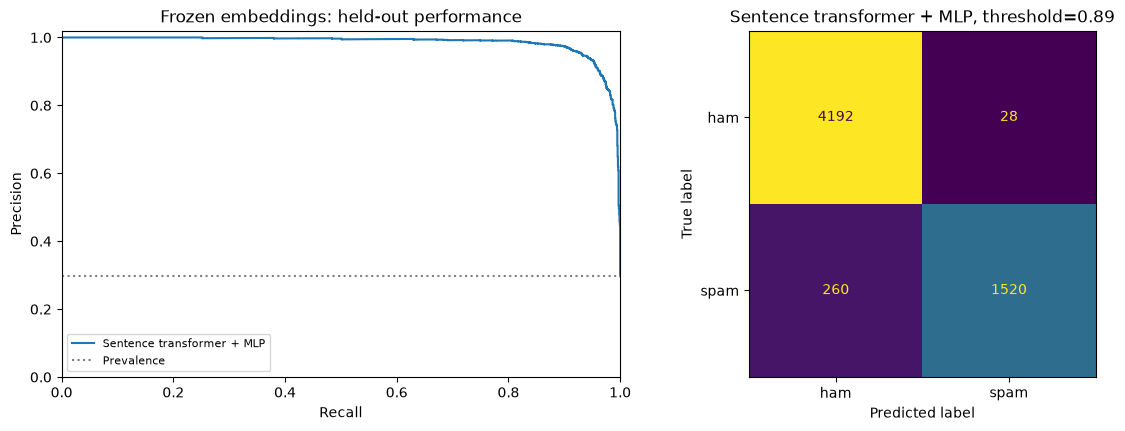

Compare with the earlier test table; do not reload XGBoost into this embedding evaluation.
Exploratory comparison: this test set was already inspected in earlier experiments.


In [ ]:
print('11d. Evaluate the frozen embedding classifier without loading other model libraries', flush=True)


def embedding_metric_record(targets, probabilities, threshold):
    predictions = probabilities >= threshold
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        targets, predictions, labels=[0, 1]).ravel()
    return {'threshold': threshold,
            'average_precision': average_precision_score(targets, probabilities),
            'precision': precision_score(targets, predictions, zero_division=0),
            'recall': recall_score(targets, predictions, zero_division=0),
            'f1': f1_score(targets, predictions, zero_division=0),
            'false_positives': int(false_positive), 'false_negatives': int(false_negative),
            'flagged_fraction': float(predictions.mean()),
            'cost_per_1000': 1000 * (5 * false_positive + false_negative) / len(targets)}


embedding_test_probability = embedding_classifier.predict_proba(embedding_matrices['test'])[:, 1]
print('Embedding test prediction completed.', flush=True)
embedding_comparison_records = {'Prior baseline': embedding_metric_record(
    embedding_test_labels, np.full(len(test), embedding_train_labels.mean()), 0.5)}
embedding_comparison_records['Sentence transformer + MLP'] = embedding_metric_record(
    embedding_test_labels, embedding_test_probability, embedding_threshold)
embedding_test_results = pd.DataFrame(embedding_comparison_records).T
model_directory = DATA_DIR / 'models'
model_directory.mkdir(exist_ok=True)
embedding_artifact_path = model_directory / 'sentence_transformer_mlp.joblib'
joblib.dump({'classifier': embedding_classifier, 'threshold': embedding_threshold,
             'embedding_settings': embedding_settings, 'seed': SEED,
             'label_meanings': LABEL_MEANINGS, 'versions': {**versions, **embedding_versions},
             'input_schema': ['subject', 'body'],
             'reference_dataset_file': str(email_data_path.relative_to(REPO_ROOT))},
            embedding_artifact_path)
restored_embedding_artifact = joblib.load(embedding_artifact_path)
embedding_test_results.to_csv(model_directory / 'sentence_transformer_mlp_test_metrics.csv')
np.savez_compressed(model_directory / 'sentence_transformer_mlp_test_predictions.npz',
                    probabilities=embedding_test_probability, labels=embedding_test_labels,
                    source_rows=test['source_row'].to_numpy())
print('Classifier, encoder settings, test metrics, and predictions saved.', flush=True)
display(embedding_test_results.round(4))
figure, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
curve_precision, curve_recall, unused_thresholds = precision_recall_curve(
    embedding_test_labels, embedding_test_probability)
axes[0].step(curve_recall, curve_precision, where='post', label='Sentence transformer + MLP')
axes[0].axhline(embedding_test_labels.mean(), color='gray', linestyle=':', label='Prevalence')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Frozen embeddings: held-out performance',
            xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(embedding_test_labels,
                                        embedding_test_probability >= embedding_threshold,
                                        display_labels=['ham', 'spam'], ax=axes[1], colorbar=False)
axes[1].set_title(f'Sentence transformer + MLP, threshold={embedding_threshold:.2f}')
plt.show()
print('Compare with the earlier test table; do not reload XGBoost into this embedding evaluation.')
print('Exploratory comparison: this test set was already inspected in earlier experiments.')

## Optional extension: does another hidden layer help?

Compare two networks using the same 16 email features:

| Network | Structure | Trainable parameters |
|---|---|---:|
| One hidden layer | 16 inputs → 16 ReLU units → 1 sigmoid output | 289 |
| Two hidden layers | 16 inputs → 16 ReLU units → 16 ReLU units → 1 sigmoid output | 561 |

Use the main experiment's prepared, scaled inputs—not the separate embedding-only session. Both networks use the same splits, seed, Adam optimizer, regularization and 200-epoch limit. The one-hidden-layer baseline is trained again; earlier models and thresholds are not overwritten.

Choose each threshold on validation data using the same 5:1 error costs, then compare test precision, recall and error counts. **More layers also mean more parameters**, so this does not test depth alone.

Treat the results as exploratory: this is one seed, training may not converge and the test set was already inspected. A reliable choice needs repeated runs and fresh evaluation data—not more tuning on this test set.

[Official MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)

12. Exploratory depth comparison: one versus two hidden layers
One hidden layer weight shapes: [(16, 16), (16, 1)]
Two hidden layers weight shapes: [(16, 16), (16, 16), (16, 1)]


,hidden_layers,parameters,epochs,threshold,validation_ap,validation_cost_per_1000,warnings
model,,,,,,,
One hidden layer,"(16,)",289,200,0.82,0.8353,232.8333,1
Two hidden layers,"(16, 16)",561,200,0.84,0.8601,217.5000,1


Frozen validation thresholds; exploratory historical test comparison (not a fresh holdout).


,threshold,precision,recall,f1,average_precision,false_positives,false_negatives,cost_per_1000
model,,,,,,,,
One hidden layer,0.82,0.9245,0.3921,0.5507,0.8356,57,1082,227.8333
Two hidden layers,0.84,0.9232,0.5331,0.6759,0.8667,79,831,204.3333


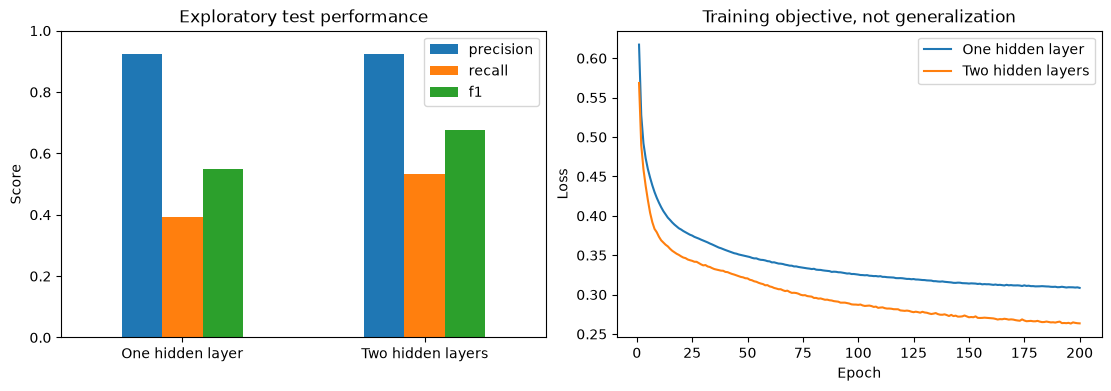

One seed only; greater depth also changes capacity. No test-driven retuning. Confirm on fresh data.


In [ ]:
print('12. Exploratory depth comparison: one versus two hidden layers')
required_depth_inputs = ['X_train', 'X_validation', 'X_test', 'y_train', 'y_validation', 'y_test']
missing_depth_inputs = [name for name in required_depth_inputs if name not in globals()]
if missing_depth_inputs:
    raise RuntimeError('Run sections 1-5 first; missing: ' + ', '.join(missing_depth_inputs))

from sklearn.metrics import average_precision_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.exceptions import ConvergenceWarning
import warnings

depth_models = {}
depth_thresholds = {}
depth_validation_records = []
for depth_name, hidden_layers in [('One hidden layer', (16,)), ('Two hidden layers', (16, 16))]:
    depth_candidate = MLPClassifier(
        hidden_layer_sizes=hidden_layers, activation='relu', solver='adam',
        alpha=0.01, batch_size=128, learning_rate_init=0.001,
        max_iter=200, n_iter_no_change=15, early_stopping=False, random_state=SEED)
    with warnings.catch_warnings(record=True) as depth_caught:
        warnings.simplefilter('always', ConvergenceWarning)
        depth_candidate.fit(X_train, y_train)
    depth_validation_probability = depth_candidate.predict_proba(X_validation)[:, 1]
    depth_cost_candidates = []
    for depth_threshold in np.linspace(0.05, 0.95, 91):
        depth_tn, depth_fp, depth_fn, depth_tp = confusion_matrix(
            y_validation, depth_validation_probability >= depth_threshold, labels=[0, 1]).ravel()
        depth_cost_candidates.append((5 * depth_fp + depth_fn, float(depth_threshold)))
    depth_validation_cost, depth_selected_threshold = min(depth_cost_candidates)
    depth_models[depth_name] = depth_candidate
    depth_thresholds[depth_name] = depth_selected_threshold
    depth_parameters = sum(weights.size for weights in depth_candidate.coefs_) + sum(
        biases.size for biases in depth_candidate.intercepts_)
    depth_validation_records.append({
        'model': depth_name, 'hidden_layers': str(hidden_layers), 'parameters': depth_parameters,
        'epochs': depth_candidate.n_iter_, 'threshold': depth_selected_threshold,
        'validation_ap': average_precision_score(y_validation, depth_validation_probability),
        'validation_cost_per_1000': 1000 * depth_validation_cost / len(y_validation),
        'warnings': len(depth_caught)})
    print(depth_name, 'weight shapes:', [weights.shape for weights in depth_candidate.coefs_])
    for depth_warning in depth_caught:
        print(type(depth_warning.message).__name__ + ':', str(depth_warning.message))
depth_validation_results = pd.DataFrame(depth_validation_records).set_index('model')
display(depth_validation_results.round(4))

print('Frozen validation thresholds; exploratory historical test comparison (not a fresh holdout).')
depth_test_records = []
for depth_name, depth_candidate in depth_models.items():
    depth_probability = depth_candidate.predict_proba(X_test)[:, 1]
    depth_prediction = depth_probability >= depth_thresholds[depth_name]
    depth_tn, depth_fp, depth_fn, depth_tp = confusion_matrix(y_test, depth_prediction, labels=[0, 1]).ravel()
    depth_test_records.append({
        'model': depth_name, 'threshold': depth_thresholds[depth_name],
        'precision': precision_score(y_test, depth_prediction, zero_division=0),
        'recall': recall_score(y_test, depth_prediction, zero_division=0),
        'f1': f1_score(y_test, depth_prediction, zero_division=0),
        'average_precision': average_precision_score(y_test, depth_probability),
        'false_positives': depth_fp, 'false_negatives': depth_fn,
        'cost_per_1000': 1000 * (5 * depth_fp + depth_fn) / len(y_test)})
depth_test_results = pd.DataFrame(depth_test_records).set_index('model')
display(depth_test_results.round(4))
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
depth_test_results[['precision', 'recall', 'f1']].plot.bar(ax=axes[0], rot=0, ylim=(0, 1))
axes[0].set(title='Exploratory test performance', ylabel='Score', xlabel='')
for depth_name, depth_candidate in depth_models.items():
    axes[1].plot(np.arange(1, len(depth_candidate.loss_curve_) + 1), depth_candidate.loss_curve_, label=depth_name)
axes[1].set(title='Training objective, not generalization', xlabel='Epoch', ylabel='Loss')
axes[1].legend()
plt.show()
print('One seed only; greater depth also changes capacity. No test-driven retuning. Confirm on fresh data.')

### Jupyter notebook --footer info--

Operating system, date/time and Python version for this notebook session.

In [ ]:
import os
import platform
from datetime import datetime
from platform import python_version

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('-----------------------------------')